In [1]:
%%capture _municipios
# Re-run the analysis notebooks; every number in this report comes from their variables.
%run "analise_municipios.ipynb"

In [2]:
# Keep what this report needs from analise_municipios before the next notebook runs.
annual = df_por_ano["areakm"].copy()                 # km² per year; 2000 = deforestation up to 2000
total = total_desmatamento                          # km², up to 2023
up_to_2000 = total_desmatamento_00
from_2001 = total_desmatamento_01_23
cerrado_area = area_cerrado_maranhense              # km²
state_area = area_estado_ma
mun = gdf_mun_cerrado.copy()
mun_map = gdf_mun_cerrado_recortado.copy()

In [3]:
%%capture _microregioes
%run "analise_microregioes.ipynb"

In [4]:
%%capture _grade
%run "analise_grade_micro.ipynb"

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import HTML, display

plt.close("all")
import matplotlib as mpl
mpl.rcdefaults()          # the analysis notebooks switch on a seaborn theme
%config InlineBackend.figure_formats = ["svg"]

micro = df_micro_desmatamento.copy()
grid = df_grade.copy()                      # analise_grade_micro already drops the invalid cell 44316
grid["pct_2023"] = grid["d2000"] + grid["d001_23"]
micro["abs_2000"] = micro["area_cerra"] * micro["d2000"] / 100
micro["abs_2001_23"] = micro["area_cerra"] * micro["d01-23"] / 100
micro["abs_2023"] = micro["abs_2000"] + micro["abs_2001_23"]
micro["pct_2023"] = micro["d2000"] + micro["d01-23"]
micro = micro.sort_values("d01-23", ascending=False)

t3 = mun.sort_values("D2000-23_km2", ascending=False).head(15)   # Table 3: total deforestation up to 2023
t3_alt = mun.sort_values("D2001-23_km2", ascending=False).head(15)  # ranking used for the sums in the article text
t4 = mun.sort_values("D2001-23_perc", ascending=False).head(15)  # Table 4: increase in deforested share

y = annual.drop(2000)
by_name = mun.set_index("NM_MUN")
mic = micro.set_index("NM_MICRO")

km = lambda x: f"{x:,.0f}"
pct = lambda x, d=0: f"{100 * x:.{d}f}%"

In [6]:
# The text of this report quotes the values below. Stop the build if the analysis changes.
assert round(total) == 89880 and round(up_to_2000) == 41357 and round(from_2001) == 48523
assert cerrado_area == 217029 and round(total / cerrado_area, 3) == 0.414
assert round(from_2001 / total, 2) == 0.54
assert (y.idxmax(), round(y.max())) == (2007, 2962)
assert (y.idxmin(), round(y.min())) == (2016, 1281)
assert round(y.loc[2011]) == 1440 and round(y.loc[2023]) == 2928
assert all(y.loc[2020:2023].diff().dropna() > 0) and round(y.loc[2019]) == 1341
assert len(mun) == 139 and len(micro) == 14
assert [round(mic.loc["Presidente Dutra", c]) for c in ("d2000", "pct_2023")] == [44, 82]
assert list(micro["NM_MICRO"][:3]) == ["Presidente Dutra", "Caxias", "Chapadinha"]
assert (micro["d2000"] < 20).sum() == 10 and (micro["pct_2023"] > 40).sum() == 7
assert list(micro.loc[micro["pct_2023"] < 20, "NM_MICRO"]) == ["Lençóis Maranhenses"]
assert round(mic.loc["Médio Mearim", "d2000"]) == 93 and micro["NM_MICRO"].iloc[-1] == "Médio Mearim"
assert micro.sort_values("abs_2001_23").iloc[-1]["NM_MICRO"] == "Gerais de Balsas"
assert round(mic.loc["Gerais de Balsas", "abs_2001_23"], -2) == 8000
assert micro.sort_values("abs_2023").iloc[-1]["NM_MICRO"] == "Alto Mearim e Grajaú"
assert list(t3["NM_MUN"][:2]) == ["Balsas", "Grajaú"] and round(by_name.loc["Balsas", "D2001-23_km2"]) == 3581
assert [round(by_name.loc["Carolina", c]) for c in ("D2000_km2", "D2000-23_km2")] == [273, 1566]
assert round(by_name.loc["Carolina", "VariacaoAbsoluta"], 2) == 4.73
assert round(t3["D2001-23_km2"].sum()) == 20701 and round(t3["D2001-23_km2"].sum() / from_2001, 3) == 0.427
assert round(t3_alt["D2001-23_km2"].sum()) == 21139 and len(set(t3["NM_MUN"]) & set(t3_alt["NM_MUN"])) == 13
assert t4["NM_MUN"].iloc[0] == "Governador Eugênio Barros"
assert [round(100 * by_name.loc["Governador Eugênio Barros", c]) for c in ("D2000_Perc", "D2000-23_perc")] == [26, 89]
assert round(t4["AREA_KM2"].sum()) == 16539 and round(t4["D2001-23_km2"].sum()) == 6911
assert len(grid) == 2805 and 44316 not in set(grid["id"])
assert ((grid["d2000"] < 20).sum(), (grid["pct_2023"] < 20).sum()) == (2016, 855)
assert ((grid["d2000"] >= 80).sum(), (grid["pct_2023"] >= 80).sum()) == (215, 407)
assert round((grid["d2000"] < 20).mean(), 2) == 0.72 and round((grid["pct_2023"] < 20).mean(), 2) == 0.30
assert round(t4["AREA_KM2"].sum() / cerrado_area, 3) == 0.076 and round(t4["D2001-23_km2"].sum() / from_2001, 3) == 0.142

In [7]:
display(HTML("""
<style>
:root { --ink:#0b0b0b; --ink-2:#52514e; --rule:#d9d8d3; --accent:#2a78d6; --paper:#ffffff; }
html, body { background: var(--paper) !important; }
body, .jp-Notebook, .jp-RenderedHTMLCommon {
  font-family: "Charter", "Bitstream Charter", "Georgia", "DejaVu Serif", serif !important;
  color: var(--ink) !important; font-size: 10.5pt !important; line-height: 1.5 !important;
}
.jp-Notebook { max-width: 168mm; margin: 0 auto !important; padding: 0 !important; }
.jp-Cell, .jp-Cell-outputWrapper, .jp-OutputArea, .jp-OutputArea-child, .jp-OutputArea-output,
.jp-RenderedHTMLCommon, .jp-MarkdownOutput { padding: 0 !important; margin: 0 !important; overflow: visible !important; }
.jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }
.jp-OutputArea-child { display: block !important; }
.jp-RenderedHTMLCommon p { margin: 0 0 0.6em !important; text-align: justify; hyphens: auto; }
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3 {
  font-family: "Inter", "Helvetica Neue", Arial, sans-serif !important; color: var(--ink) !important;
  break-after: avoid; }
.jp-RenderedHTMLCommon h1 { font-size: 17pt !important; line-height: 1.25 !important; margin: 0 0 0.3em !important; font-weight: 700; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt !important; margin: 1.3em 0 0.4em !important; font-weight: 650;
  border-bottom: 1px solid var(--rule); padding-bottom: 2px; }
.jp-RenderedHTMLCommon h3 { font-size: 10.5pt !important; margin: 1em 0 0.3em !important; font-weight: 600; }
.jp-RenderedHTMLCommon a { color: var(--accent) !important; text-decoration: none; }
.jp-RenderedHTMLCommon .anchor-link { display: none !important; }
.jp-RenderedHTMLCommon code { font-size: 9pt; background: #f2f1ee; padding: 0 3px; border-radius: 3px; }
.jp-RenderedHTMLCommon ul, .jp-RenderedHTMLCommon ol { margin: 0 0 0.6em 1.2em !important; }
.jp-RenderedHTMLCommon li { margin: 0 0 0.2em !important; }
.subtitle { font-family: "Inter", Arial, sans-serif; color: var(--ink-2); font-size: 10.5pt; margin-bottom: 1em; }
.authors { font-family: "Inter", Arial, sans-serif; font-size: 9.5pt; line-height: 1.45; margin-bottom: 1em; }
.authors .aff { color: var(--ink-2); }
.note { font-family: "Inter", Arial, sans-serif; font-size: 8.5pt; color: var(--ink-2);
  border-left: 3px solid var(--accent); background: #f5f8fd; padding: 6px 10px; margin: 0 0 1em; }
.abstract { border-top: 1px solid var(--rule); border-bottom: 1px solid var(--rule); padding: 8px 0 4px; margin-bottom: 1em; }
.abstract p { font-size: 10pt; }
.caption { font-family: "Inter", Arial, sans-serif; font-size: 8.5pt; color: var(--ink-2); margin: 0.9em 0 0.3em; break-after: avoid; }
.caption b { color: var(--ink); }
.source { font-family: "Inter", Arial, sans-serif; font-size: 7.5pt; color: var(--ink-2); margin: 0.2em 0 1em; }
.jp-RenderedHTMLCommon table.report-table { border-collapse: collapse !important; table-layout: auto !important;
  font-family: "Inter", Arial, sans-serif; font-size: 8pt !important; font-variant-numeric: tabular-nums;
  margin: 0 !important; width: 100%; break-inside: avoid; }
.jp-RenderedHTMLCommon .report-table th, .jp-RenderedHTMLCommon .report-table td {
  padding: 2.5px 5px !important; border: none; text-align: right !important; white-space: nowrap;
  line-height: 1.3 !important; max-width: none !important; }
.jp-RenderedHTMLCommon .report-table .left { text-align: left !important; white-space: normal; }
.jp-RenderedHTMLCommon .report-table .group { text-align: center !important; }
.jp-RenderedHTMLCommon .report-table tbody tr:hover { background: inherit; }
.report-table thead th { border-bottom: 1px solid var(--ink); font-weight: 600; vertical-align: bottom; }
.report-table tbody tr:last-child td, .report-table tbody tr:last-child th { border-bottom: 1px solid var(--ink); }
.report-table tbody tr:nth-child(even) { background: #f7f7f5; }
.report-table .pt { color: var(--ink-2); }
.report-table .diag { background: #dce9fa; font-weight: 600; }
.report-table .total { font-weight: 600; border-top: 1px solid var(--ink-2); }
.report-table thead .group { border-bottom: 1px solid var(--rule) !important; }
figure, .jp-OutputArea-output svg { break-inside: avoid; }
.jp-RenderedSVG, .jp-RenderedImage { text-align: center; padding: 0 !important; }
.jp-RenderedSVG svg { max-width: 100%; height: auto; }
.refs p { font-size: 8.5pt; text-align: left; margin-bottom: 0.4em !important; padding-left: 1.5em; text-indent: -1.5em; }
.pagebreak { break-before: page; }
</style>
"""))

# Expansion of deforestation in the Cerrado of Maranhão, Brazil, 2001–2023

<div class="subtitle">Companion report — a reproducible English summary of Correia et al. (2026), <i>Revista Tocantinense de Geografia</i>, 15(35), 45–67</div>

<div class="authors">
Luís Fernando Cirqueira da Silva Correia · Thomas Victor de Sousa Malheiros Rocha · Denilson da Silva Bezerra · Celso Henrique Leite Silva Junior · Sérgio Souza Costa<br>
<span class="aff">Universidade Federal do Maranhão (UFMA), São Luís, Brazil · Contact: sergio.costa@ufma.br</span>
</div>

<div class="note">
This report is built from <code>report_en.ipynb</code>, which re-runs the analysis notebooks <code>analise_municipios.ipynb</code>,
<code>analise_microregioes.ipynb</code> and <code>analise_grade_micro.ipynb</code> on the data in the repository
<a href="https://github.com/LambdaGeo/analise-cerrado-ma">github.com/LambdaGeo/analise-cerrado-ma</a>.
Every number, table and figure is computed when the report is built. It summarizes the peer-reviewed article,
published in Portuguese: <a href="https://doi.org/10.70860/rtg.v15i35.19356">doi:10.70860/rtg.v15i35.19356</a>.
Please cite the article.
</div>

<div class="abstract">

**Abstract.** The Cerrado covers about two thirds of the state of Maranhão, and in recent years the state has become one of the main fronts of deforestation in Brazil. Using PRODES Cerrado data from INPE, we examined the absolute and relative evolution of deforestation in the Cerrado of Maranhão from 2001 to 2023, by biome, microregion and municipality. By 2023, 89,880 km² had been deforested, 41% of the Cerrado in the state, and 54% of that area was cleared from 2001 onwards. Annual clearing fell after 2008 and stayed between about 1,300 and 1,900 km² a year from 2011 to 2019, then rose every year from 2020, reaching 2,928 km² in 2023. Deforestation spread over the whole biome rather than only the south of the state: on a regular grid, which removes the effect of the size of administrative units, the share of cells with less than 20% of their area deforested fell from 72% in 2000 to 30% in 2023. Presidente Dutra, Caxias and Chapadinha were the microregions with the largest increase in deforested share; in Presidente Dutra it went from 44% to 82%. Among municipalities, Balsas had the largest deforestation from 2001 to 2023 (3,581 km²), while in Governador Eugênio Barros the deforested share of the municipality rose from 26% to 89%. The 15 municipalities with the largest relative increase cover an area equal to 8% of the Cerrado in the state but account for 14% of its deforestation since 2001.

**Keywords:** deforestation; Cerrado; PRODES; Maranhão; remote sensing.

</div>

## 1. Introduction

The Cerrado is the Brazilian savanna, a biodiversity hotspot of about two million square kilometres whose conversion to agriculture accelerated in recent decades (Strassburg et al., 2017). Clearing its deep-rooted vegetation changes carbon storage and the water cycle (Spera et al., 2016). Unlike rural properties in the Legal Amazon, which must keep 80% of their native vegetation, properties in the Cerrado need to keep only 20% (Brasil, 2012), so much of the clearing is legal.

In Maranhão the Cerrado covers about two thirds of the state. In 2023 the state rose from fifth to first place in the national deforestation ranking, and it has 13 of the 50 municipalities with the most deforestation in the last four years (MapBiomas, 2024). Reports and studies tend to focus on the large municipalities of the south of the state. This study looks at the whole Cerrado of Maranhão over more than two decades, in absolute and relative terms, to see where deforestation has been spreading.

## 2. Data and methods

**Deforestation data.** We used PRODES Cerrado (INPE), which maps the removal of native vegetation regardless of its later use or legality, as published on the TerraBrasilis platform (data downloaded in May 2024). PRODES gives the deforestation accumulated up to 2000, then increments every two years until 2012 and every year from 2013. For the biennial period, each year was given half of the two-year increment.

**Territorial units.** Deforestation was summarized for the whole Cerrado of Maranhão (217,029 km²), for the 14 IBGE microregions with more than half of their territory in the biome, for the 139 municipalities covered by PRODES Cerrado, and for a regular grid of 2,805 cells of 0.083° (about 9 km on a side), which removes the influence of unit size. For microregions the share is relative to the Cerrado area inside each microregion, for municipalities to the whole municipal area, and for grid cells to the cell area.

**Measures.** For each unit we computed the deforestation up to 2000, from 2001 to 2023, and the total up to 2023, both in km² (absolute) and as a share of the unit's area (relative).

## 3. Results

### 3.1 The biome

By 2023, 89,880 km² of the Cerrado of Maranhão had been deforested, 41% of its area. Of this, 41,357 km² had been cleared by 2000 and 48,523 km² from 2001 to 2023, so more than half of all deforestation in the biome happened in the period studied.

Annual clearing peaked at 2,962 km² in 2007–2008 (Figure 1). It then fell to 1,440 km² a year in 2011–2012 and stayed between about 1,300 and 1,900 km² until 2019, with the lowest value in 2016 (1,281 km²). From 2020 it rose every year, reaching 2,928 km² in 2023, almost back to the peak.

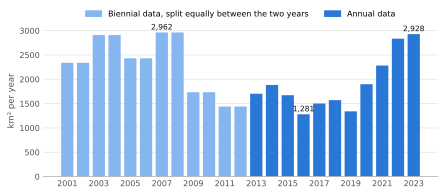

In [8]:
biennial = y.index <= 2012
fig, ax = plt.subplots(figsize=(6.3, 2.8))
ax.bar(y.index[biennial], y[biennial], width=0.78, color="#86b6ef")
ax.bar(y.index[~biennial], y[~biennial], width=0.78, color="#2a78d6")
ax.set_ylabel("km² per year", color="#52514e", fontsize=8.5)
ax.set_xticks(range(2001, 2024, 2))
ax.yaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#b5b4ad")
ax.tick_params(axis="both", labelsize=8, colors="#52514e", length=0)
ax.legend(handles=[Patch(color="#86b6ef", label="Biennial data, split equally between the two years"),
                   Patch(color="#2a78d6", label="Annual data")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=8)
for yr in (2007, 2016, 2023):
    ax.annotate(f"{y[yr]:,.0f}", (yr, y[yr]), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=7.5, color="#0b0b0b")
fig.tight_layout()
display(HTML('<div class="caption"><b>Figure 1.</b> Annual deforestation in the Cerrado of Maranhão, 2001–2023 (PRODES).</div>'))
plt.show()

### 3.2 Microregions

Deforestation grew in every microregion (Table 1). The largest increases in deforested share were in the east of the state: Presidente Dutra, where it went from 44% to 82% of the Cerrado area, Caxias and Chapadinha. Gerais de Balsas, the largest microregion, had the most deforestation in km² from 2001 to 2023 (about 8,000 km²), but ranks only tenth in relative terms. The smallest increases were in Médio Mearim, which was already 93% deforested in 2000, and in Lençóis Maranhenses, home to the national park of the same name. Figure 2 shows the shift: in 2000, 10 of the 14 microregions had less than 20% of their Cerrado cleared; by 2023 half of them had more than 40%, and only Lençóis Maranhenses remained below 20%.

In [9]:
rows = []
for _, r in micro.iterrows():
    rows.append(f"<tr><td class='left'>{r['NM_MICRO']}</td><td>{km(r['area_cerra'])}</td>"
                f"<td>{r['d2000']:.0f}%</td><td>{r['pct_2023']:.0f}%</td><td>{r['d01-23']:.0f}</td>"
                f"<td>{km(r['abs_2001_23'])}</td></tr>")
display(HTML(f"""
<div class="caption"><b>Table 1.</b> Deforestation by microregion, ordered by the increase in deforested share.</div>
<table class="report-table">
<thead>
<tr><th rowspan="2" class="left">Microregion</th><th rowspan="2">Cerrado area (km²)</th>
<th colspan="3" class="group">Deforested share of the Cerrado area</th><th rowspan="2">Deforested 2001–2023 (km²)</th></tr>
<tr><th>2000</th><th>2023</th><th>Increase (p.p.)</th></tr>
</thead>
<tbody>{''.join(rows)}</tbody>
</table>
<div class="source">p.p.: percentage points. Source: PRODES Cerrado (INPE); IBGE 2022 microregions.</div>
"""))

In [10]:
BINS = [0, 20, 40, 60, 80, 100.01]
RAMP = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
LABELS = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]

def classify(values):
    return pd.cut(values, bins=BINS, labels=False, right=False)

def choropleth(gdf, columns, titles, caption, scale=1, linewidth=0.25):
    fig, axs = plt.subplots(1, 2, figsize=(6.0, 3.5))
    for ax, col, title in zip(axs, columns, titles):
        cls = classify((gdf[col] * scale).clip(0, 100))
        gdf.plot(ax=ax, color=[RAMP[int(c)] for c in cls], edgecolor="white", linewidth=linewidth)
        ax.set_title(title, fontsize=9, color="#0b0b0b")
        ax.set_axis_off()
        ax.set_aspect("equal")
    fig.legend(handles=[Patch(facecolor=c, label=l) for c, l in zip(RAMP, LABELS)],
               loc="lower center", ncol=5, frameon=False, fontsize=8, title="Deforested share",
               title_fontsize=8, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    display(HTML(f'<div class="caption">{caption}</div>'))
    plt.show()

choropleth(micro, ["d2000", "pct_2023"], ["Up to 2000", "Up to 2023"],
           "<b>Figure 2.</b> Share of the Cerrado area of each microregion deforested up to 2000 and up to 2023.")

### 3.3 Municipalities

In absolute terms, deforestation is led by the large municipalities of the south (Table 2). Balsas had the most deforestation both in total (5,293 km² by 2023) and from 2001 to 2023 (3,581 km²), followed by Grajaú. Carolina had the largest relative growth among these municipalities: its deforested area went from 273 km² in 2000 to 1,566 km² in 2023, almost six times more. The 15 municipalities in Table 2 account for 43% of the deforestation from 2001 to 2023.

In [11]:
rows = []
for i, (_, r) in enumerate(t3.iterrows(), 1):
    rows.append(f"<tr><td>{i}</td><td class='left'>{r['NM_MUN']}</td><td>{km(r['AREA_KM2'])}</td>"
                f"<td>{km(r['D2000_km2'])}</td><td>{km(r['D2000-23_km2'])}</td><td>{km(r['D2001-23_km2'])}</td>"
                f"<td>{pct(r['VariacaoAbsoluta'])}</td></tr>")
s = t3[["AREA_KM2", "D2000_km2", "D2000-23_km2", "D2001-23_km2"]].sum()
rows.append(f"<tr class='total'><td></td><td class='left'>Total</td><td>{km(s['AREA_KM2'])}</td><td>{km(s['D2000_km2'])}</td>"
            f"<td>{km(s['D2000-23_km2'])}</td><td>{km(s['D2001-23_km2'])}</td><td></td></tr>")
display(HTML(f"""
<div class="caption"><b>Table 2.</b> The 15 municipalities with the most deforestation up to 2023 (article Table 3).</div>
<table class="report-table">
<thead>
<tr><th rowspan="2">Rank</th><th rowspan="2" class="left">Municipality</th><th rowspan="2">Area (km²)</th>
<th colspan="3" class="group">Deforested (km²)</th><th rowspan="2">Growth since 2000</th></tr>
<tr><th>Up to 2000</th><th>Up to 2023</th><th>2001–2023</th></tr>
</thead>
<tbody>{''.join(rows)}</tbody>
</table>
<div class="source">Growth since 2000: deforestation from 2001 to 2023 divided by deforestation up to 2000.
These 15 municipalities cover {pct(s['AREA_KM2'] / cerrado_area, 1)} of the Cerrado area of the state and account for
{pct(s['D2001-23_km2'] / from_2001, 1)} of its deforestation from 2001 to 2023.</div>
"""))

Relative measures tell a different story (Table 3). The municipalities with the largest increase in deforested share are mostly small and lie in the east of the state, outside the rankings that usually draw attention. In Governador Eugênio Barros the deforested share went from 26% of the municipality in 2000 to 89% in 2023. Together, these 15 municipalities cover 16,539 km², 8% of the Cerrado in the state, but account for 6,911 km², 14% of the deforestation from 2001 to 2023. Figure 3 shows the same pattern: by 2023 deforestation had reached high shares across the east and centre of the biome, not only in the south.

In [12]:
rows = []
for i, (_, r) in enumerate(t4.iterrows(), 1):
    rows.append(f"<tr><td>{i}</td><td class='left'>{r['NM_MUN']}</td><td>{km(r['AREA_KM2'])}</td>"
                f"<td>{pct(r['D2000_Perc'])}</td><td>{pct(r['D2000-23_perc'])}</td><td>{pct(r['D2001-23_perc'])}</td>"
                f"<td>{km(r['D2001-23_km2'])}</td></tr>")
display(HTML(f"""
<div class="caption"><b>Table 3.</b> The 15 municipalities with the largest increase in deforested share, 2001–2023 (article Table 4).</div>
<table class="report-table">
<thead>
<tr><th rowspan="2">Rank</th><th rowspan="2" class="left">Municipality</th><th rowspan="2">Area (km²)</th>
<th colspan="3" class="group">Deforested share of the municipality</th><th rowspan="2">Deforested 2001–2023 (km²)</th></tr>
<tr><th>2000</th><th>2023</th><th>Increase</th></tr>
</thead>
<tbody>{''.join(rows)}</tbody>
</table>
<div class="source">Increase: deforestation from 2001 to 2023 as a share of the municipal area, in percentage points.</div>
"""))

In [13]:
choropleth(mun_map, ["D2000_Perc", "D2000-23_perc"], ["Up to 2000", "Up to 2023"],
           "<b>Figure 3.</b> Share of each municipality deforested up to 2000 and up to 2023, within the Cerrado of Maranhão.",
           scale=100)

### 3.4 Regular grid

The grid confirms the spread without the bias of unit size (Figure 4). In 2000, 72% of the cells (2,016 of 2,805) had less than 20% of their area deforested, and the cells cleared above 80% were concentrated in the north of the biome, around Médio Mearim and Pindaré, and along its western edge. By 2023 only 30% of the cells (855) remained below 20%, and the number of cells more than 80% deforested had almost doubled, from 215 to 407. Cells with more than 40% cleared now appear from the north to the east and the south of the biome; the main areas still mostly below 20% are a block in its centre, the far north-east and the southern tip.

In [14]:
choropleth(grid, ["d2000", "pct_2023"], ["Up to 2000", "Up to 2023"],
           "<b>Figure 4.</b> Share of each grid cell (0.083°, about 9 km) deforested up to 2000 and up to 2023 (article Figure 7).",
           linewidth=0)

## 4. Discussion and limitations

**Where deforestation is happening.** Absolute figures point to the large municipalities of the south, such as Balsas and Grajaú, which also rank third and ninth in deforestation from 2001 to 2023 in the whole Brazilian Cerrado (article Table 2, from TerraBrasilis). Relative figures show that clearing has also advanced quickly in the east, in microregions such as Presidente Dutra, Caxias and Chapadinha and in small municipalities that are close to losing all their native vegetation. Both views are needed: absolute figures favour large units and relative figures favour small ones.

**Trend.** The rise since 2020 brings annual clearing back to the levels of the late 2000s. Explaining it is beyond the scope of this exploratory study; the legal framework, which requires only 20% of native vegetation to be kept on Cerrado properties, is one factor discussed in the article.

**Units of analysis.** Municipal shares are relative to the whole municipal area, including any part outside the Cerrado, while microregion shares are relative to the Cerrado area inside each microregion. The grid map of deforestation from 2015 to 2023 (article Figure 8) and the deforestation in Indigenous Lands (article Table 5, from TerraBrasilis) are not reproduced here.

**Biennial data.** Before 2013 PRODES Cerrado is biennial, and splitting each increment equally between two years hides any difference between them.

**Notes on the published figures.** The article's text gives 21,139 km² for the deforestation of "these 15 municipalities"; that sum belongs to the ranking by deforestation from 2001 to 2023, which shares 13 municipalities with the list in Table 2 (whose sum is 20,701 km²). The conclusion is the same. The analysis uses 217,029 km² for the Cerrado of Maranhão.

## 5. Conclusions

From 2001 to 2023 the Cerrado of Maranhão lost 48,523 km² of native vegetation, more than everything cleared before 2000, and by 2023 41% of the biome in the state had been deforested. After a decline in the 2010s, clearing has risen every year since 2020. Deforestation is not limited to the south of the state or to large municipalities: on the regular grid, cells with less than 20% of their area cleared went from 72% to 30% of the biome; in relative terms the fastest losses are in the east, and the 15 municipalities with the largest relative increase account for 14% of the deforestation since 2001 while covering 8% of the biome. Future work should look at how the cleared land is being used, for example with MapBiomas land use and land cover maps.

## Reproducibility

Code, data and notebooks are in [github.com/LambdaGeo/analise-cerrado-ma](https://github.com/LambdaGeo/analise-cerrado-ma) (MIT license for the code; the data derive from INPE and IBGE and follow their terms of use). With Python 3.12 and the pinned dependencies in `requirements.txt`, the notebooks `analise_bioma.ipynb`, `analise_microregioes.ipynb`, `analise_municipios.ipynb` and `analise_grade_micro.ipynb` reproduce the published results, and `python build_report.py` rebuilds this report. The report checks the values quoted in its text against the analysis and stops if they differ.

## References

<div class="refs">

Brasil (2012). Lei nº 12.651, de 25 de maio de 2012. Dispõe sobre a proteção da vegetação nativa. *Diário Oficial da União*.

Correia, L. F. C. S.; Rocha, T. V. S. M.; Bezerra, D. S.; Silva Junior, C. H. L.; Costa, S. S. (2026). Expansão do desmatamento no cerrado maranhense entre os anos de 2001 – 2023. *Revista Tocantinense de Geografia*, 15(35), 45–67. https://doi.org/10.70860/rtg.v15i35.19356

INPE (2023). PRODES Cerrado — Monitoramento do desmatamento do Cerrado brasileiro por satélite. TerraBrasilis. https://terrabrasilis.dpi.inpe.br

MapBiomas (2024). RAD 2023: Relatório Anual do Desmatamento no Brasil. São Paulo: MapBiomas. https://alerta.mapbiomas.org

Spera, S. A. et al. (2016). Land-use change affects water recycling in Brazil's last agricultural frontier. *Global Change Biology*, 22(10), 3405–3413. https://doi.org/10.1111/gcb.13298

Strassburg, B. B. N. et al. (2017). Moment of truth for the Cerrado hotspot. *Nature Ecology & Evolution*, 1, 0099. https://doi.org/10.1038/s41559-017-0099

</div>